# 03 · Clustering

**Goal:** find the **themes** in the war's neighborhood, and how close each theme is to the war.

These are two separate questions with two separate answers:

| Question | Answered by |
|---|---|
| Which articles belong together? (theme) | **clustering** on Milne–Witten similarity between articles (Step 2) |
| How close is an article to the war? (closeness) | each article's similarity to the seed (`seed_similarity`, Step 2) |

Article metadata (length, links, whether a template added the seed's link) **describes** the clusters but isn't used to form them. Length would group articles by size rather than topic, and `from_template` would just rebuild the navboxes. Keeping it out lets us test whether the clusters are navboxes in disguise.

The seed is left out (788 articles). It's linked to everything, so it would be every article's neighbor. The clustering functions are in `src/clustering.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import squareform
from sklearn.metrics import adjusted_rand_score, silhouette_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import clustering
import similarity

pd.set_option("display.max_colwidth", 120)
SEED = "Hundred Years' War"
K = 10  # neighbors per article in the graph

data = ROOT / "data" / "processed"
pairs = pd.read_parquet(data / "pairs.parquet")
pairs = pairs[(pairs["a"] != SEED) & (pairs["b"] != SEED)]
mw = similarity.from_pairs(pairs, "milne_witten")
distance = 1 - mw.to_numpy()
print(f"Milne–Witten similarity: {mw.shape[0]} × {mw.shape[1]} articles (seed excluded)")

Milne–Witten similarity: 788 × 788 articles (seed excluded)


## 1. The neighbor graph

Almost every pair of articles has some similarity: the in-link half alone has a median of 0.49. A graph with all 310,000 pairs as edges would be one dense ball. So each article keeps only its **K = 10 most similar articles** (a **k-nearest-neighbor graph**), with edges weighted by similarity. An edge chosen by either end stays, so popular articles end up with more than 10 edges.

K controls how fine the grouping is: fewer neighbors split the graph into more, smaller groups. Section 3 checks how much the result depends on it.

In [2]:
graph = clustering.knn_graph(mw, K)
degree = pd.Series(dict(graph.degree()))
print(f"{graph.number_of_nodes()} articles | {graph.number_of_edges():,} edges | "
      f"{nx.number_connected_components(graph)} connected component(s)")
print(f"edges per article: median {degree.median():.0f}, max {degree.max()} ({degree.idxmax()})")

788 articles | 6,243 edges | 1 connected component(s)
edges per article: median 13, max 74 (Hastilude)


## 2. Louvain communities

**Louvain** is a standard algorithm for finding **communities** in a graph: groups of nodes with more edge weight inside than between them. It maximizes **modularity**, which is the edge weight that falls inside groups minus the amount expected if the same edges were placed at random. Unlike k-means, it picks the number of groups itself.

Each cluster below is shown with its 6 most **central** articles: those with the highest average similarity to the rest of their cluster.

In [3]:
labels = clustering.louvain(graph)
centrality = pd.Series(
    {t: mw.loc[t, labels.index[labels == c]].drop(t).mean() for t, c in labels.items()}, name="centrality"
)

def top_members(c, n=6):
    members = centrality[labels == c].sort_values(ascending=False)
    return " | ".join(members.index[:n])

print(f"{labels.nunique()} clusters")
pd.DataFrame({
    "articles": labels.value_counts().sort_index(),
    "most central articles": [top_members(c) for c in sorted(labels.unique())],
})

12 clusters


,articles,most central articles
cluster,,
0,120,"Battle of Caen (1346) | Hundred Years' War, 1345–1347 | Crécy campaign | Battle of Blanchetaque | Battle of Ardres |..."
1,119,High Middle Ages | History of Western civilization | Late Middle Ages | Early Middle Ages | Crusading movement | Ris...
2,88,Henry IV of England | House of Plantagenet | Richard II of England | Henry V of England | List of English monarchs |...
3,78,Hastilude | Disability in the Middle Ages | Great Famine of 1315–1317 | Itinerant court | List of common misconcepti...
4,67,"Name of Joan of Arc | Trial of Joan of Arc | I, Joan | Equestrian statue of Joan of Arc (Paris) | Jacques d'Arc | Pi..."
5,63,Second Hundred Years' War | Anglo-French Wars | Battle of Brémule | Gascon War | Anglo-French War (1627–1629) | Angl...
6,63,Siege of Saint-Denis (1435) | Siege of Rouen (1418–1419) | Battle of Patay | Siege of Paris (1435–1436) | Battle of ...
7,59,Battle of Auray | Battle of Cocherel | Battle of La Rochelle | Battle of Pontvallain | Siege of Rennes (1356–1357) |...
8,58,Charles IV of France | Philip V of France | Louis X of France | Philip VI of France | John II of France | John I of ...


### Naming the clusters
The names come from reading the table above. Each name is tied to one member article rather than to a cluster number, because Louvain's numbering can change between runs.

In [4]:
NAMES = {
    "Crécy campaign": "Edwardian phase (1337–1360)",
    "Siege of Rouen (1418–1419)": "Lancastrian phase (1415–1453)",
    "War of the Breton Succession": "Brittany and the Caroline phase",
    "Trial of Joan of Arc": "Joan of Arc",
    "Henry V of England": "English monarchy",
    "Philip VI of France": "French monarchy and feudalism",
    "Burgundian State": "Burgundy and the Low Countries",
    "Anglo-French Wars": "Other Anglo-French wars",
    "High Middle Ages": "The Middle Ages in Europe",
    "Hastilude": "Medieval society and culture",
    "Bordeaux": "Towns and regions",
    "Medieval warfare": "War in general",
}
cluster_name = {labels[article]: name for article, name in NAMES.items()}
assert len(cluster_name) == len(NAMES) == labels.nunique(), "every cluster needs exactly one name"
names = labels.map(cluster_name).rename("cluster_name")
names.value_counts().to_frame("articles")

,articles
cluster_name,
Edwardian phase (1337–1360),120
The Middle Ages in Europe,119
English monarchy,88
Medieval society and culture,78
Joan of Arc,67
Lancastrian phase (1415–1453),63
Other Anglo-French wars,63
Brittany and the Caroline phase,59
French monarchy and feudalism,58


## 3. Evaluation

There are no labels to score against, so three checks stand in:

- **Separation (silhouette):** for each article, compare its average distance to its own cluster with its average distance to the nearest other cluster. The score runs from −1 to 1, and higher means better separated. Distance = 1 − similarity.
- **Stability:** rerun with different random seeds, and on random 80% of the articles. Do the same groups come back?
- **Robustness:** do the groups survive a different K?

Agreement between two clusterings is measured by the **adjusted Rand index (ARI)**: 1 for the same grouping, about 0 for agreement no better than chance. It doesn't care what the clusters are numbered.

### Silhouette, and its trap
For comparison, **hierarchical clustering** works on the distances directly. It repeatedly merges the two closest groups. *Average* linkage measures group distance by the average pair; *complete* linkage uses the farthest pair.

In [5]:
condensed = squareform(distance, checks=False)
louvain_labels = labels[mw.index].to_numpy()
n = labels.nunique()

candidates = {"Louvain": louvain_labels}
for method, k in [("average", 5), ("average", n), ("complete", n)]:
    candidates[f"hierarchical, {method} linkage, {k} clusters"] = fcluster(linkage(condensed, method), k, "maxclust")

def summarize(cluster_labels):
    sizes = np.sort(np.bincount(cluster_labels))[::-1]
    sizes = sizes[sizes > 0]
    return {
        "silhouette": silhouette_score(distance, cluster_labels, metric="precomputed"),
        "largest cluster": sizes[0],
        "clusters of 1": (sizes == 1).sum(),
        "ARI vs Louvain": adjusted_rand_score(louvain_labels, cluster_labels),
    }

pd.DataFrame({name: summarize(c) for name, c in candidates.items()}).T.round(2)

,silhouette,largest cluster,clusters of 1,ARI vs Louvain
Louvain,0.21,120.0,0.0,1.00
"hierarchical, average linkage, 5 clusters",0.28,765.0,2.0,-0.00
"hierarchical, average linkage, 12 clusters",0.17,695.0,4.0,0.02
"hierarchical, complete linkage, 12 clusters",0.21,298.0,0.0,0.30


**The trap:** average linkage with 5 clusters gets the *best* silhouette, yet it puts almost every article in one cluster. Silhouette rewards a few distant outliers split off from one big group, so it can't be the only check. Louvain's silhouette is modest: the themes overlap (a king belongs to his dynasty *and* to his battles), and silhouette measures how cleanly clusters separate, not whether they make sense. Complete linkage matches Louvain's silhouette, but it still has one cluster of almost 300 articles and only partly agrees with Louvain. Louvain is kept because its groups are readable themes and, as shown next, stable.

### Stability and robustness

In [6]:
by_seed = [clustering.louvain(graph, seed=s) for s in range(1, 11)]
by_subset = clustering.stability(mw, labels, K, n_runs=20, frac=0.8)
by_k = {k: clustering.louvain(clustering.knn_graph(mw, k)) for k in (5, 15)}

pd.DataFrame({
    "ARI vs main clustering": [
        np.mean([adjusted_rand_score(labels, s[labels.index]) for s in by_seed]),
        by_subset.mean(),
        adjusted_rand_score(labels, by_k[5][labels.index]),
        adjusted_rand_score(labels, by_k[15][labels.index]),
    ],
    "clusters": [
        f"{min(s.nunique() for s in by_seed)}–{max(s.nunique() for s in by_seed)}",
        "",
        by_k[5].nunique(),
        by_k[15].nunique(),
    ],
}, index=["10 other random seeds (mean)", "20 random 80% subsets (mean)", "K = 5 neighbors", "K = 15 neighbors"]).round(2)

,ARI vs main clustering,clusters
10 other random seeds (mean),0.89,11–13
20 random 80% subsets (mean),0.79,
K = 5 neighbors,0.65,16
K = 15 neighbors,0.77,11


## 4. Cluster profiles

Now the metadata comes in, to describe each theme:

- **median seed rank:** the median of the cluster's ranks in similarity to the seed (1 = most similar, out of 788). This is closeness.
- **linked from a template:** the share of the cluster that the seed links to only through a template (navbox, sidebar).
- **links back to the seed:** the share whose page links to the war.
- **median words:** article length.

In [7]:
articles = pd.read_parquet(data / "articles.parquet").set_index("title")
seed_similarity = pd.read_parquet(data / "seed_similarity.parquet").set_index("title")
links = pd.read_parquet(data / "links.parquet")
seed_links = links[links["source"] == SEED].drop_duplicates("target").set_index("target")

profile_data = pd.DataFrame({
    "cluster_name": names,
    "seed_rank": seed_similarity["milne_witten_rank"],
    "from_template": seed_links["from_template"].astype(float),
    "links_to_seed": articles["links_to_seed"].astype(float),
    "word_count": articles["word_count"],
}).loc[labels.index]

profile = profile_data.groupby("cluster_name").agg(**{
    "articles": ("seed_rank", "size"),
    "median seed rank": ("seed_rank", "median"),
    "linked from a template": ("from_template", "mean"),
    "links back to the seed": ("links_to_seed", "mean"),
    "median words": ("word_count", "median"),
}).sort_values("median seed rank")
profile.round(2)

,articles,median seed rank,linked from a template,links back to the seed,median words
cluster_name,,,,,
Lancastrian phase (1415–1453),63,229.0,0.54,0.90,870.0
Medieval society and culture,78,253.5,0.94,0.85,3388.0
Joan of Arc,67,257.0,0.88,0.96,675.0
The Middle Ages in Europe,119,356.0,0.82,0.82,6667.0
Brittany and the Caroline phase,59,408.0,0.44,0.73,1043.0
English monarchy,88,478.5,0.22,0.41,3382.5
Other Anglo-French wars,63,482.0,0.78,0.62,2701.0
French monarchy and feudalism,58,495.0,0.14,0.50,1550.5
Burgundy and the Low Countries,23,528.0,0.35,0.39,1683.0


## 5. The picture

A **force-directed layout** draws the neighbor graph with each edge acting as a spring whose strength is the pair's similarity. All nodes also repel each other. Positions are a 2D squeeze of the full similarity table, and they change with the random start, so only neighborhoods mean something, not distances across the picture.

With 12 clusters, 12 colors would be hard to tell apart. So the layout is drawn 12 times, each copy highlighting one cluster, with its most central article labeled.

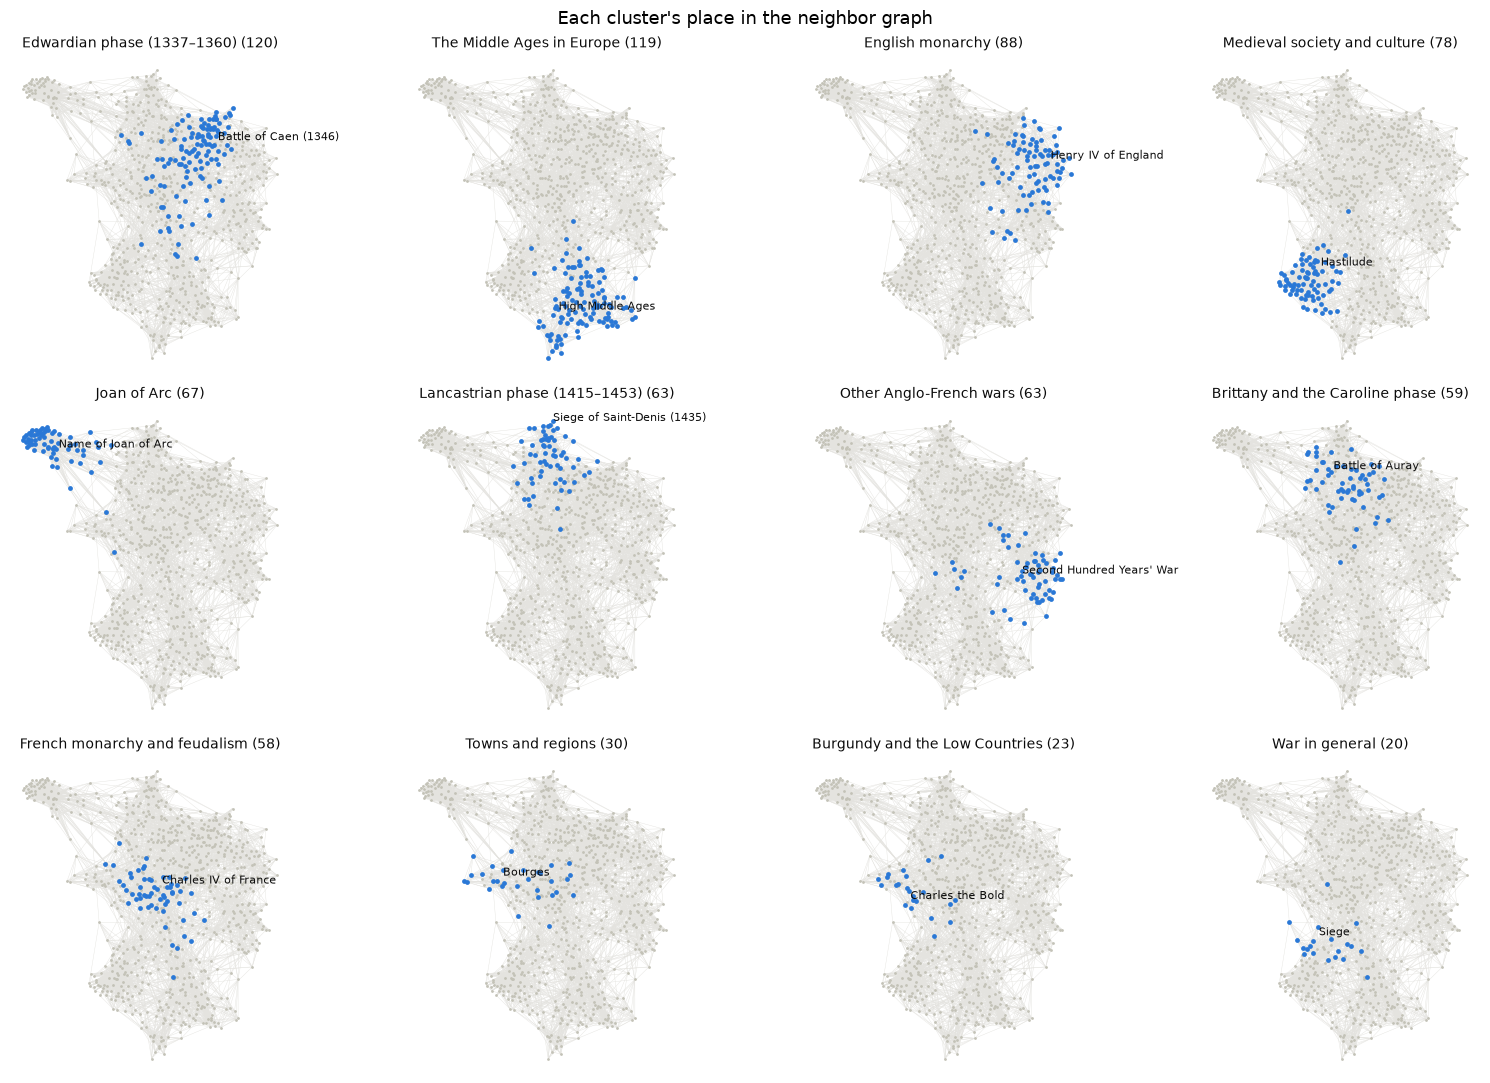

In [8]:
pos = nx.spring_layout(graph, weight="weight", seed=0)
xy = np.array([pos[t] for t in labels.index])
edges = np.array([(pos[u], pos[v]) for u, v in graph.edges()])

order = names.value_counts().index
fig, axes = plt.subplots(3, 4, figsize=(15, 11))
for ax, name in zip(axes.flat, order):
    inside = (names == name).to_numpy()
    ax.add_collection(plt.matplotlib.collections.LineCollection(edges, colors="#e4e3df", linewidths=0.3, zorder=0))
    ax.scatter(*xy[~inside].T, s=4, color="#c3c2b7", linewidths=0, zorder=1)
    ax.scatter(*xy[inside].T, s=12, color="#2a78d6", linewidths=0, zorder=2)
    hub = centrality[names == name].idxmax()
    ax.annotate(hub, pos[hub], xytext=(4, 4), textcoords="offset points", fontsize=8, color="#0b0b0b", zorder=3)
    ax.set_title(f"{name} ({inside.sum()})", fontsize=10, color="#0b0b0b")
    ax.set_axis_off()
fig.suptitle("Each cluster's place in the neighbor graph", fontsize=13)
plt.tight_layout()

### Bridge articles
Some articles are pulled between themes. An article's **outside share** is the fraction of its 10 most similar articles that sit in other clusters. Most articles have none (median 0). The highest are bridges, where an article's label and its neighborhood disagree.

In [9]:
outside = clustering.outside_share(mw, labels, K)
neighbor_names = names[mw.index].to_numpy()[clustering.neighbors(mw, K)]

def main_outside_cluster(title):
    row = neighbor_names[mw.index.get_loc(title)]
    others = pd.Series(row[row != names[title]])
    return others.mode().iloc[0] if len(others) else ""

bridges = outside.sort_values(ascending=False).head(10).index
pd.DataFrame({
    "outside share": outside[bridges],
    "cluster": names[bridges],
    "most neighbors outside are in": [main_outside_cluster(t) for t in bridges],
})

,outside share,cluster,most neighbors outside are in
Feudalism,1.0,French monarchy and feudalism,The Middle Ages in Europe
Battle of Jargeau,0.9,Lancastrian phase (1415–1453),Joan of Arc
Kingdom of France,0.9,Other Anglo-French wars,The Middle Ages in Europe
Piracy,0.8,War in general,The Middle Ages in Europe
Military history of France,0.8,Other Anglo-French wars,French monarchy and feudalism
Duchy of Aquitaine,0.8,Towns and regions,French monarchy and feudalism
Urban T. Holmes Jr.,0.8,Edwardian phase (1337–1360),Joan of Arc
Harelle,0.8,English monarchy,Edwardian phase (1337–1360)
Armagnac–Burgundian Civil War,0.8,Burgundy and the Low Countries,Lancastrian phase (1415–1453)
Castilian Civil War of 1351–1369,0.8,Brittany and the Caroline phase,Lancastrian phase (1415–1453)


## 6. Save

`clusters.parquet`: one row per article (seed excluded) with its cluster number, name, centrality and outside share, for the graph in Step 4.

In [10]:
clusters = pd.DataFrame({
    "cluster": labels, "cluster_name": names, "centrality": centrality, "outside_share": outside,
}).loc[labels.index].rename_axis("title").reset_index()

assert len(clusters) == 788 and clusters["title"].is_unique, "one row per article"
assert SEED not in set(clusters["title"]), "seed excluded"
assert clusters["cluster_name"].notna().all(), "every article named"
assert clusters.set_index("title")["cluster"].equals(clustering.louvain(graph).rename_axis("title")), "reproducible"

clusters.to_parquet(data / "clusters.parquet", index=False)
clusters.to_csv(data / "clusters.csv", index=False, encoding="utf-8-sig")
print(f"saved clusters ({len(clusters)} rows, {clusters['cluster'].nunique()} clusters)")

saved clusters (788 rows, 12 clusters)


## Findings

- **12 readable themes:**
  - the war's three phases: Edwardian, Brittany and the Caroline phase, Lancastrian
  - Joan of Arc
  - the English and French monarchies
  - Burgundy and the Low Countries
  - other Anglo-French wars
  - the Middle Ages in Europe and medieval society
  - towns and regions
  - war in general
- **The clusters are stable:**
  - ARI 0.89 across random seeds (11 to 13 clusters)
  - ARI 0.79 on random 80% subsets
  - ARI 0.77 with K = 15 neighbors
  - With K = 5, the clusters split into 16 smaller ones (ARI 0.65).
- **Silhouette alone misleads:** hierarchical clustering with average linkage scores higher (0.28 vs Louvain's 0.21), even though it puts 765 of the 788 articles in one cluster.
- **Theme and closeness differ:**
  - Closest to the seed (median rank about 230 to 260): the Lancastrian phase, Joan of Arc and medieval society.
  - Farthest (570 to 690): the Edwardian phase, towns and regions, and war in general.
  - The Edwardian cluster is far partly because it holds many short articles (median about 860 words), half of which don't link back to the war. It also absorbs citation sources: publishers are its least central members.
- **Partly navboxes, not only navboxes:**
  - The seed links to 94% of *Medieval society* only through a template, yet that cluster ranks second closest to the seed. This is the navbox echo from Step 2.
  - The two monarchies and the towns are 0–22% template-linked, so most of the structure isn't navboxes.
- **Bridges:**
  - *Battle of Jargeau* sits in the Lancastrian phase, but 9 of its 10 nearest articles are in other clusters, mostly Joan of Arc.
  - *Feudalism* and *Kingdom of France* sit between their cluster and the Middle Ages.